In [2]:
!pip install mne --break-system-packages

In [3]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [4]:
!pip install pyedflib
!pip install scipy
!pip install pandas
!pip install numpy
!pip install matplotlib

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
import pyedflib
import os
import warnings
warnings.filterwarnings('ignore')

# Seizure (given in the data)
seizures_chb01 = [
    {'file': 'chb01_03.edf', 'start': 2996, 'end': 3036},
]

# Setup
data_dir = '../data/chb01/'  
sfreq = 256  # Sampling frequency (given by CHB-MIT)
n_channels = 23

print(f"Sampling frequency: {sfreq} Hz")
print(f"Number of channels: {n_channels}")

Sampling frequency: 256 Hz
Number of channels: 23


In [6]:
# function to extract eeg from an edf file
def extract_eeg_from_file(filename, channel_idx):
    """
    Load one channel of EEG from an EDF file.
    
    Parameters:
    - filename: name of .edf file (e.g., 'chb01_03.edf')
    - channel_idx: which channel to load (0-22 for 23 channels)
    
    Returns:
    - eeg_signal: numpy array of EEG samples
    
    Example:
    eeg_ch0 = extract_eeg_from_file('chb01_03.edf', 0)
    eeg_ch5 = extract_eeg_from_file('chb01_03.edf', 5)
    """

    # Combine the folder path with filename to create complete file path
    filepath = os.path.join(data_dir, filename)

    f = pyedflib.EdfReader(filepath)

    # Read the signal from one specific channel (0-22)
    eeg_signal = f.readSignal(channel_idx)
    
    f.close()
    
    return eeg_signal
    # will ultimately return a vector of eeg numbers (each number is the electrical voltage of the brain)
    

In [7]:
# define feature extraction functions
def calculate_entropy(signal_segment):
   
    
    # Create histogram of signal values (divide into 50 bins)
    # This shows the distribution of voltage values
    hist, _ = np.histogram(signal_segment, bins=50)
    
    # Normalize histogram to probability distribution (they should al sum to 1)
    # converting the counts into probabilities
    hist = hist / np.sum(hist)
    
    # Remove zero values
    # Keep only bins with actual data
    hist = hist[hist > 0]

    # use the entropy formula
    entropy_val = -np.sum(hist * np.log2(hist))

    return entropy_val
    

In [8]:
# line length extraction
def calculate_line_length(signal_segment):
    
    # Calculate difference between consecutive samples
    # np.diff subtracts each value from the next one
    # Example: [100, 102, 101] → [102-100=2, 101-102=-1] → [2, -1]
    # creates a numpy array
    differences = np.diff(signal_segment)
    
    # Take absolute value (we care about magnitude, not direction)
    # Negative differences (going down) count same as positive (going up)
    # Example: [2, -1] → [2, 1]
    absolute_differences = np.abs(differences)
    
    # Sum all the changes together
    line_length_val = np.sum(absolute_differences)
    
    return line_length_val

In [9]:
def calculate_high_freq_power(signal_segment, sfreq = 256):

    # Determines window size for power spectral density calculation
    nperseg = min(1024, len(signal_segment))

    # Calculate power spectral density using Welch's method
    f, pxx = signal.welch(signal_segment, sfreq, nperseg=nperseg)
    
    # Extract frequencies above 20 Hz
    high_freq_band = pxx[f >= 20]
    
    # Sum all the power in the high-frequency band
    high_freq_power = np.sum(high_freq_band)
    
    return high_freq_power

In [10]:
def extract_features(signal_segment, sfreq=256):
    # Extract all three features from one EEG segment at once.
    
    
    entropy_val = calculate_entropy(signal_segment)
    
    
    line_length_val = calculate_line_length(signal_segment)
    
    
    high_freq_val = calculate_high_freq_power(signal_segment, sfreq)
    
    
    return entropy_val, line_length_val, high_freq_val



In [39]:

def extract_features_sliding(eeg, sfreq, start_sec, end_sec, window_sec, step_sec):
    # Initialize lists to store results
    times = []
    entropies = []
    line_lengths = []
    high_freqs = []
    
    # Start at the beginning of the period
    current_time = start_sec

    while current_time + window_sec <= end_sec:
        # Convert seconds to sample indices (samples = seconds multiplied by th sampling_rate)
        start_idx = int(current_time * sfreq)
        end_idx = int((current_time + window_sec) * sfreq)

        # Extract the EEG signal for this window
        # seg = EEG data from start_idx to end_idx
        # collect the data from only that window
        
        seg = eeg[start_idx:end_idx]

        # Process if we have valid data
        if len(seg) > 0:
            
            # Extract all three features from this window
            e, ll, hf = extract_features(seg, sfreq)
            
            # Store measurements
            times.append(current_time - start_sec)
            entropies.append(e)
            line_lengths.append(ll)
            high_freqs.append(hf)
        
        # Move to the next measurement point
        current_time += step_sec
    
    # Return all of thw measurements
    return times, entropies, line_lengths, high_freqs

        

In [59]:
# extract form 23 channels
seizure = seizures_chb01[0]
eeg_all_channels = []


# Load each of the 23 channels
for ch in range(n_channels):
    try:
        # Try to load this channel
        ch_signal = extract_eeg_from_file(seizure['file'], ch)
        eeg_all_channels.append(ch_signal)
        print(f"Loaded channel {ch:2d} ({len(ch_signal)} samples)")
    except Exception as e:
        # If error, print it and append None
        print(f"Error loading channel")
        eeg_all_channels.append(None)

# Count successful loads
successful_channels = len([c for c in eeg_all_channels if c is not None])
print(f"\nTotal channels loaded: {successful_channels}/{n_channels}")

# Get seizure timing information
sz_start = seizure['start']
sz_end = seizure['end']

# Define baseline reference period (10-12 minutes into recording)
baseline_start = 600
baseline_end = 720

print(f"\nSeizure information:")
print(f"  File: {seizure['file']}")
print(f"  Start: {sz_start} seconds")
print(f"  End: {sz_end} seconds")
print(f"  Duration: {sz_end - sz_start} seconds")
print(f"\nBaseline reference period: {baseline_start}-{baseline_end} seconds (10-12 minutes)")

Loaded channel  0 (921600 samples)
Loaded channel  1 (921600 samples)
Loaded channel  2 (921600 samples)
Loaded channel  3 (921600 samples)
Loaded channel  4 (921600 samples)
Loaded channel  5 (921600 samples)
Loaded channel  6 (921600 samples)
Loaded channel  7 (921600 samples)
Loaded channel  8 (921600 samples)
Loaded channel  9 (921600 samples)
Loaded channel 10 (921600 samples)
Loaded channel 11 (921600 samples)
Loaded channel 12 (921600 samples)
Loaded channel 13 (921600 samples)
Loaded channel 14 (921600 samples)
Loaded channel 15 (921600 samples)
Loaded channel 16 (921600 samples)
Loaded channel 17 (921600 samples)
Loaded channel 18 (921600 samples)
Loaded channel 19 (921600 samples)
Loaded channel 20 (921600 samples)
Loaded channel 21 (921600 samples)
Loaded channel 22 (921600 samples)

Total channels loaded: 23/23

Seizure information:
  File: chb01_03.edf
  Start: 2996 seconds
  End: 3036 seconds
  Duration: 40 seconds

Baseline reference period: 600-720 seconds (10-12 minute

In [102]:
#Approach A: 30 minute windows for both
print("Approach A: 30 minute windows")
# Define time windows for 30-minute approach

seizure = seizures_all[0]
sz_start = seizure['start']  # 2996
sz_end = seizure['end']      # 3036

baseline_30_start = baseline_start
baseline_30_end = baseline_start + 1800 # 1800 seconds = 30 minutes
preictal_30_start = sz_start - 1800
preictal_30_end = sz_start
print(f"\nBaseline window: {baseline_30_start}-{baseline_30_end} seconds (30 min)")
print(f"Preictal window: {preictal_30_start}-{preictal_30_end} seconds (30 min)")
print()
# Store results for each channel
results_30min = {}
# Process each of the 23 channels
for ch in range(n_channels):
    # Skip if channel failed to load
    if eeg_all_channels[ch] is None:
        print(f"Channel {ch:2d}: SKIPPED (failed to load)")
        continue
    
    # Get this channel's EEG data
    eeg = eeg_all_channels[ch]
    # 6 windows 
    
    # Extract features from baseline using sliding windows
    t_b, e_b, ll_b, hf_b = extract_features_sliding(
        eeg, sfreq,
        baseline_30_start, baseline_30_end,
        window_sec=60,
        step_sec=60
    )
    
    # Extract features from preictal using sliding windows
    t_p, e_p, ll_p, hf_p = extract_features_sliding(
        eeg, sfreq,
        preictal_30_start, preictal_30_end,
        window_sec=60,
        step_sec=60
    )
    
    # Calculate average feature values across all windows
    entropy_baseline = np.mean(e_b)
    line_length_baseline = np.mean(ll_b)
    hf_baseline = np.mean(hf_b)
    
    entropy_preictal = np.mean(e_p)
    line_length_preictal = np.mean(ll_p)
    hf_preictal = np.mean(hf_p)
    
    # Calculate percent change from baseline to preictal
    if entropy_baseline != 0:
        entropy_change = (entropy_preictal - entropy_baseline) / entropy_baseline * 100
    else:
        entropy_change = 0
    
    if line_length_baseline != 0:
        ll_change = (line_length_preictal - line_length_baseline) / line_length_baseline * 100
    else:
        ll_change = 0
    
    if hf_baseline != 0:
        hf_change = (hf_preictal - hf_baseline) / hf_baseline * 100
    else:
        hf_change = 0
    
    # Store all results for this channel
    results_30min[ch] = {
        'entropy_baseline': entropy_baseline,
        'entropy_preictal': entropy_preictal,
        'entropy_change_%': entropy_change,
        'line_length_baseline': line_length_baseline,
        'line_length_preictal': line_length_preictal,
        'line_length_change_%': ll_change,
        'hf_baseline': hf_baseline,
        'hf_preictal': hf_preictal,
        'hf_change_%': hf_change,
    }
    
    # Print progress for this channel
    print(f"Channel {ch:2d}: Entropy {entropy_change:+6.2f}% | Line Length {ll_change:+6.2f}% | High-Freq {hf_change:+6.2f}%")

print(f"baseline_start = {baseline_start}")
print(f"sz_start = {sz_start}")

Approach A: 30 minute windows

Baseline window: 600-2400 seconds (30 min)
Preictal window: 1196-2996 seconds (30 min)

Channel  0: Entropy  -3.38% | Line Length  -8.96% | High-Freq +16.48%
Channel  1: Entropy  -3.00% | Line Length  -5.83% | High-Freq +15.97%
Channel  2: Entropy  -1.08% | Line Length  -7.07% | High-Freq  +7.66%
Channel  3: Entropy  -1.45% | Line Length  -3.14% | High-Freq  +3.41%
Channel  4: Entropy  -2.76% | Line Length -10.52% | High-Freq +12.73%
Channel  5: Entropy  -2.75% | Line Length  -6.48% | High-Freq  +9.19%
Channel  6: Entropy  -2.10% | Line Length  -3.01% | High-Freq  +6.95%
Channel  7: Entropy  -0.16% | Line Length  -2.41% | High-Freq  +2.37%
Channel  8: Entropy  -3.43% | Line Length -14.34% | High-Freq  +9.81%
Channel  9: Entropy  -0.73% | Line Length -11.61% | High-Freq  +2.22%
Channel 10: Entropy  -1.74% | Line Length  -5.95% | High-Freq  +1.71%
Channel 11: Entropy  -0.63% | Line Length -12.24% | High-Freq -20.61%
Channel 12: Entropy  -1.68% | Line Length

In [103]:
# Approach B: 2 minute windows


seizure = seizures_all[0]
sz_start = seizure['start']  # 2996
sz_end = seizure['end']      # 3036

baseline_2_start = baseline_start
baseline_2_end = baseline_start + 120

preictal_2_start = sz_start - 120
preictal_2_end = sz_start

print(f"\nBaseline window: {baseline_2_start}-{baseline_2_end} seconds (2 min)")
print(f"Preictal window: {preictal_2_start}-{preictal_2_end} seconds (2 min)")
print()

# Store results for each channel
results_2min = {}

# Process each of the 23 channels
for ch in range(n_channels):
    # Skip if channel failed to load
    if eeg_all_channels[ch] is None:
        print(f"did not load properly, failed ot load")
        continue
    
    # Get this channel's EEG data
    eeg = eeg_all_channels[ch]

    # Number of windows = (end_sec - start_sec) / step_sec

    # 4 windows
    
    # Extract features from baseline using sliding windows
    t_b, e_b, ll_b, hf_b = extract_features_sliding(
        eeg, sfreq,
        baseline_2_start, baseline_2_end,
        window_sec=30,
        step_sec=30
    )
    
    # Extract features from preictal using sliding windows
    t_p, e_p, ll_p, hf_p = extract_features_sliding(
        eeg, sfreq,
        preictal_2_start, preictal_2_end,
        window_sec=30,
        step_sec=30
    )
    
    # Calculate average feature values across all windows
    entropy_baseline = np.mean(e_b)
    line_length_baseline = np.mean(ll_b)
    hf_baseline = np.mean(hf_b)
    
    entropy_preictal = np.mean(e_p)
    line_length_preictal = np.mean(ll_p)
    hf_preictal = np.mean(hf_p)
    
    # Calculate percent change from baseline to preictal
    if entropy_baseline != 0:
        entropy_change = (entropy_preictal - entropy_baseline) / entropy_baseline * 100
    else:
        entropy_change = 0
    
    if line_length_baseline != 0:
        ll_change = (line_length_preictal - line_length_baseline) / line_length_baseline * 100
    else:
        ll_change = 0
    
    if hf_baseline != 0:
        hf_change = (hf_preictal - hf_baseline) / hf_baseline * 100
    else:
        hf_change = 0
    
    # Store all results for this channel
    results_2min[ch] = {
        'entropy_baseline': entropy_baseline,
        'entropy_preictal': entropy_preictal,
        'entropy_change_%': entropy_change,
        'line_length_baseline': line_length_baseline,
        'line_length_preictal': line_length_preictal,
        'line_length_change_%': ll_change,
        'hf_baseline': hf_baseline,
        'hf_preictal': hf_preictal,
        'hf_change_%': hf_change,
    }
    
    # Print progress for this channel
    print(f"Channel {ch:2d}: Entropy {entropy_change:+6.2f}% | Line Length {ll_change:+6.2f}% | High-Freq {hf_change:+6.2f}%")

    




Baseline window: 600-720 seconds (2 min)
Preictal window: 2876-2996 seconds (2 min)

Channel  0: Entropy  +0.23% | Line Length -12.60% | High-Freq -12.11%
Channel  1: Entropy  -2.08% | Line Length  -9.43% | High-Freq +11.68%
Channel  2: Entropy  -1.21% | Line Length -15.25% | High-Freq  +7.29%
Channel  3: Entropy  -1.86% | Line Length  -7.71% | High-Freq +10.69%
Channel  4: Entropy  -4.88% | Line Length  -7.60% | High-Freq  -0.92%
Channel  5: Entropy  -3.66% | Line Length  -6.74% | High-Freq +13.27%
Channel  6: Entropy  -1.61% | Line Length  -0.75% | High-Freq  +8.01%
Channel  7: Entropy  -0.09% | Line Length  -1.36% | High-Freq  +9.07%
Channel  8: Entropy  -5.95% | Line Length -10.16% | High-Freq +12.37%
Channel  9: Entropy  +3.11% | Line Length -12.84% | High-Freq  +3.92%
Channel 10: Entropy  -7.02% | Line Length  -6.40% | High-Freq  +4.10%
Channel 11: Entropy  -0.78% | Line Length -27.98% | High-Freq -47.94%
Channel 12: Entropy  +3.42% | Line Length  -8.81% | High-Freq  -7.88%
Chan

AVERAGE CHANGES ACROSS ALL 23 CHANNELS:

Entropy:
  30-min: -1.39%
  2-min:  -0.59%

Line Length:
  30-min: -7.06%
  2-min:  -11.16%

High-Freq Power:
  30-min: +2.52%
  2-min:  -2.17%



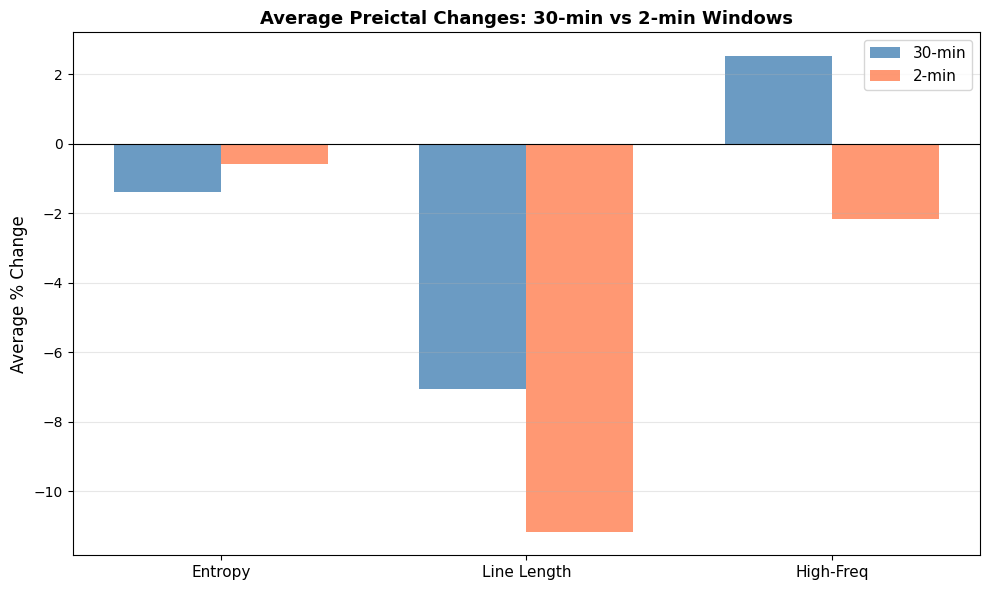

INTERPRETATION

 ENTROPY: 30-min approach shows LARGER changes
  30-min average: -1.39%
  2-min average: -0.59%

 LINE LENGTH: 2-min approach shows LARGER changes
  30-min average: -7.06%
  2-min average: -11.16%

 HIGH-FREQ POWER: 30-min approach shows LARGER changes
  30-min average: +2.52%
  2-min average: -2.17%
Conlcusion from this is to use 2-minute windows since line length and high-freq power decrease at a bigger scale, entropy has only a slight increase


In [104]:

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Channel': range(n_channels),
    'Entropy_30min': [results_30min[ch]['entropy_change_%'] for ch in range(n_channels)],
    'Entropy_2min': [results_2min[ch]['entropy_change_%'] for ch in range(n_channels)],
    'LineLength_30min': [results_30min[ch]['line_length_change_%'] for ch in range(n_channels)],
    'LineLength_2min': [results_2min[ch]['line_length_change_%'] for ch in range(n_channels)],
    'HighFreq_30min': [results_30min[ch]['hf_change_%'] for ch in range(n_channels)],
    'HighFreq_2min': [results_2min[ch]['hf_change_%'] for ch in range(n_channels)],
})

# Calculate averages
entropy_30_avg = comparison_df['Entropy_30min'].mean()
entropy_2_avg = comparison_df['Entropy_2min'].mean()

ll_30_avg = comparison_df['LineLength_30min'].mean()
ll_2_avg = comparison_df['LineLength_2min'].mean()

hf_30_avg = comparison_df['HighFreq_30min'].mean()
hf_2_avg = comparison_df['HighFreq_2min'].mean()

# Print summary
print("AVERAGE CHANGES ACROSS ALL 23 CHANNELS:\n")
print(f"Entropy:")
print(f"  30-min: {entropy_30_avg:+.2f}%")
print(f"  2-min:  {entropy_2_avg:+.2f}%\n")

print(f"Line Length:")
print(f"  30-min: {ll_30_avg:+.2f}%")
print(f"  2-min:  {ll_2_avg:+.2f}%\n")

print(f"High-Freq Power:")
print(f"  30-min: {hf_30_avg:+.2f}%")
print(f"  2-min:  {hf_2_avg:+.2f}%\n")

# Create single visualization
fig, ax = plt.subplots(figsize=(10, 6))

# Data
features = ['Entropy', 'Line Length', 'High-Freq']
approach_30 = [entropy_30_avg, ll_30_avg, hf_30_avg]
approach_2 = [entropy_2_avg, ll_2_avg, hf_2_avg]

x = np.arange(len(features))
width = 0.35

# Create bars
ax.bar(x - width/2, approach_30, width, label='30-min', alpha=0.8, color='steelblue')
ax.bar(x + width/2, approach_2, width, label='2-min', alpha=0.8, color='coral')

# Formatting
ax.axhline(0, color='black', linestyle='-', linewidth=0.8)
ax.set_ylabel('Average % Change', fontsize=12)
ax.set_title('Average Preictal Changes: 30-min vs 2-min Windows', fontweight='bold', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(features, fontsize=11)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('window_size_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("INTERPRETATION")

if abs(entropy_30_avg) > abs(entropy_2_avg):
    print("\n ENTROPY: 30-min approach shows LARGER changes")
    print(f"  30-min average: {entropy_30_avg:+.2f}%")
    print(f"  2-min average: {entropy_2_avg:+.2f}%")
else:
    print("\n ENTROPY: 2-min approach shows LARGER changes")
    print(f"  30-min average: {entropy_30_avg:+.2f}%")
    print(f"  2-min average: {entropy_2_avg:+.2f}%")

if abs(ll_30_avg) > abs(ll_2_avg):
    print("\n LINE LENGTH: 30-min approach shows LARGER changes")
    print(f"  30-min average: {ll_30_avg:+.2f}%")
    print(f"  2-min average: {ll_2_avg:+.2f}%")
else:
    print("\n LINE LENGTH: 2-min approach shows LARGER changes")
    print(f"  30-min average: {ll_30_avg:+.2f}%")
    print(f"  2-min average: {ll_2_avg:+.2f}%")

if abs(hf_30_avg) > abs(hf_2_avg):
    print("\n HIGH-FREQ POWER: 30-min approach shows LARGER changes")
    print(f"  30-min average: {hf_30_avg:+.2f}%")
    print(f"  2-min average: {hf_2_avg:+.2f}%")
else:
    print("\n HIGH-FREQ POWER: 2-min approach shows LARGER changes")
    print(f"  30-min average: {hf_30_avg:+.2f}%")
    print(f"  2-min average: {hf_2_avg:+.2f}%")

print("Conlcusion from this is to use 2-minute windows since line length and high-freq power decrease at a bigger scale, entropy has only a slight increase")

In [105]:

channels = list(results_2min.keys())  # [0, 1, 2, ... 22]

entropy_changes = [results_2min[ch]['entropy_change_%'] for ch in channels]
ll_changes      = [results_2min[ch]['line_length_change_%'] for ch in channels]
hf_changes      = [results_2min[ch]['hf_change_%'] for ch in channels]

print(f"Number of channels: {len(channels)}")
print(f"Entropy changes:    {[round(x,1) for x in entropy_changes]}")
print(f"Line length changes:{[round(x,1) for x in ll_changes]}")
print(f"High-freq changes:  {[round(x,1) for x in hf_changes]}")

Number of channels: 23
Entropy changes:    [np.float64(0.2), np.float64(-2.1), np.float64(-1.2), np.float64(-1.9), np.float64(-4.9), np.float64(-3.7), np.float64(-1.6), np.float64(-0.1), np.float64(-5.9), np.float64(3.1), np.float64(-7.0), np.float64(-0.8), np.float64(3.4), np.float64(5.4), np.float64(1.6), np.float64(2.7), np.float64(-1.9), np.float64(-2.6), np.float64(-1.2), np.float64(0.1), np.float64(1.0), np.float64(2.1), np.float64(1.6)]
Line length changes:[np.float64(-12.6), np.float64(-9.4), np.float64(-15.3), np.float64(-7.7), np.float64(-7.6), np.float64(-6.7), np.float64(-0.7), np.float64(-1.4), np.float64(-10.2), np.float64(-12.8), np.float64(-6.4), np.float64(-28.0), np.float64(-8.8), np.float64(-8.6), np.float64(-16.2), np.float64(-28.2), np.float64(-10.5), np.float64(-14.0), np.float64(-15.3), np.float64(-3.3), np.float64(-5.6), np.float64(-11.1), np.float64(-16.2)]
High-freq changes:  [np.float64(-12.1), np.float64(11.7), np.float64(7.3), np.float64(10.7), np.float64(-

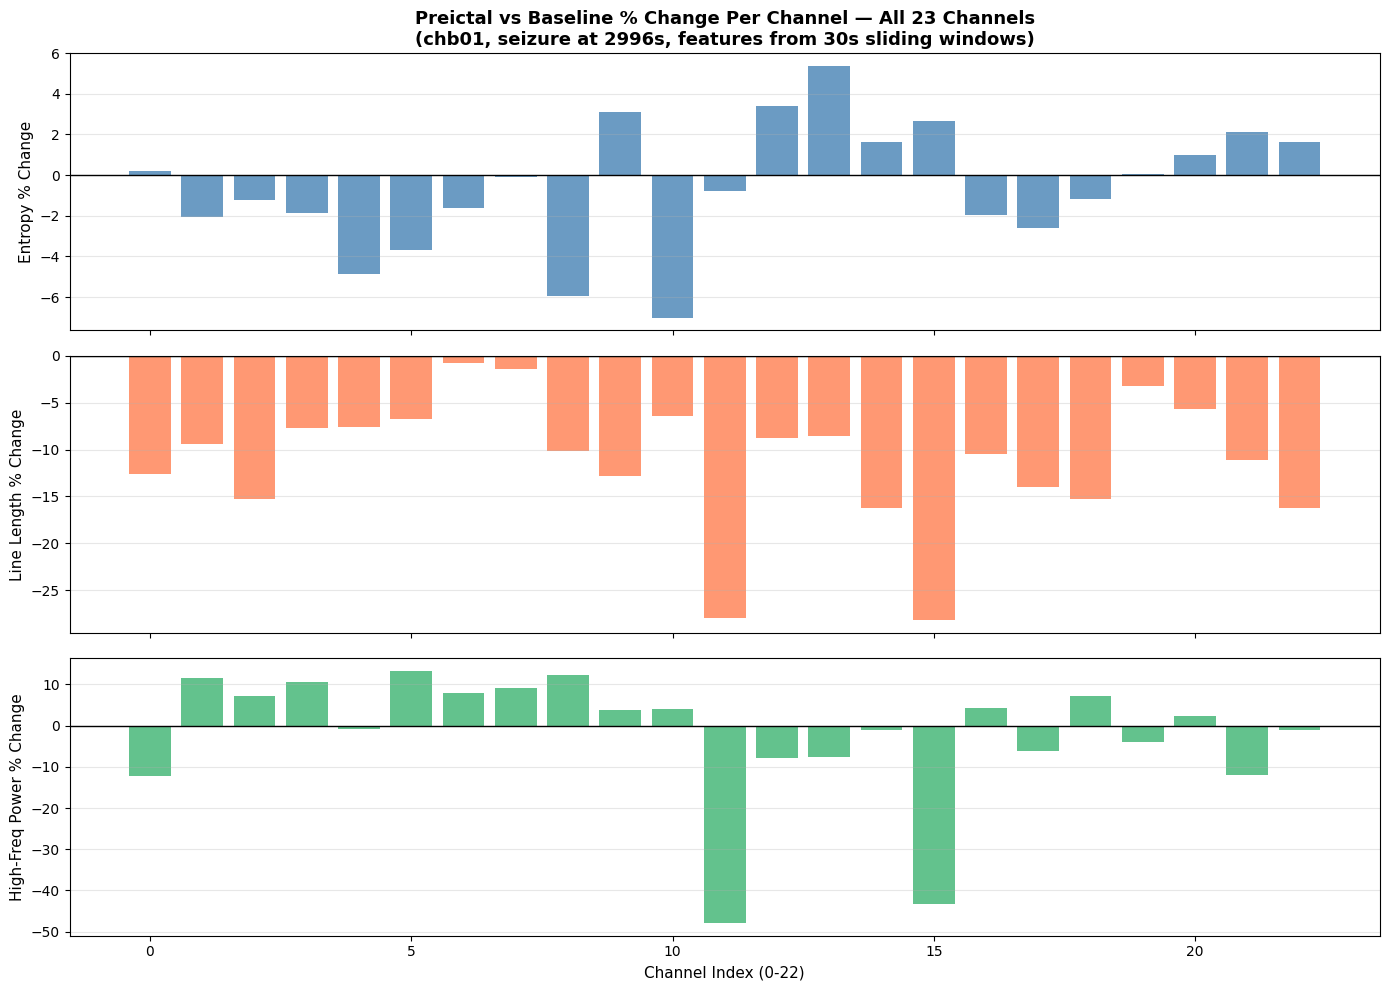

In [76]:

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

features = [entropy_changes, ll_changes, hf_changes]
labels   = ['Entropy % Change', 'Line Length % Change', 'High-Freq Power % Change']
colors   = ['steelblue', 'coral', 'mediumseagreen']

for ax, data, label, color in zip(axes, features, labels, colors):
    ax.bar(channels, data, color=color, alpha=0.8)
    ax.axhline(0, color='black', linewidth=1.0)
    ax.set_ylabel(label, fontsize=11)
    ax.grid(True, alpha=0.3, axis='y')

axes[0].set_title('Preictal vs Baseline % Change Per Channel — All 23 Channels\n(chb01, seizure at 2996s, features from 30s sliding windows)',
                  fontsize=13, fontweight='bold')
axes[2].set_xlabel('Channel Index (0-22)', fontsize=11)

plt.tight_layout()
plt.savefig('per_channel_feature_changes.png', dpi=300, bbox_inches='tight')
plt.show()

In [106]:

seizures_all = [
    {'file': 'chb01_03.edf', 'start': 2996, 'end': 3036},
    {'file': 'chb01_04.edf', 'start': 1467, 'end': 1494},
    {'file': 'chb01_15.edf', 'start': 1732, 'end': 1772},
    {'file': 'chb01_16.edf', 'start': 1015, 'end': 1066},
    {'file': 'chb01_18.edf', 'start': 1720, 'end': 1810},
    {'file': 'chb01_21.edf', 'start': 327,  'end': 420},
    {'file': 'chb01_26.edf', 'start': 1862, 'end': 1963},
]

print(f"Total seizures for chb01: {len(seizures_all)}")
for i, sz in enumerate(seizures_all):
    duration = sz['end'] - sz['start']
    print(f"  Seizure {i+1}: {sz['file']} | {sz['start']}s → {sz['end']}s | duration: {duration}s")

Total seizures for chb01: 7
  Seizure 1: chb01_03.edf | 2996s → 3036s | duration: 40s
  Seizure 2: chb01_04.edf | 1467s → 1494s | duration: 27s
  Seizure 3: chb01_15.edf | 1732s → 1772s | duration: 40s
  Seizure 4: chb01_16.edf | 1015s → 1066s | duration: 51s
  Seizure 5: chb01_18.edf | 1720s → 1810s | duration: 90s
  Seizure 6: chb01_21.edf | 327s → 420s | duration: 93s
  Seizure 7: chb01_26.edf | 1862s → 1963s | duration: 101s


In [107]:
import os
files = sorted(os.listdir('../data/chb01/'))
for f in files:
    print(f)

chb01-summary.txt
chb01_03.edf
chb01_04.edf
chb01_15.edf
chb01_16.edf
chb01_18.edf
chb01_21.edf
chb01_26.edf


In [108]:
# Extract features for all 7 seizures, 0-120s baseline, no exclusions
all_seizure_results = {}
valid_seizures = []

for sz_idx, seizure in enumerate(seizures_all):
    sz_start = seizure['start']
    sz_end   = seizure['end']
    
    b_start = 0
    b_end   = 120
    
    preictal_start = sz_start - 120
    preictal_end   = sz_start
    
    gap = sz_start - b_end

    MIN_GAP_SEC = 1200  # 20 minutes

    gap = sz_start - b_end
    if gap < MIN_GAP_SEC:
        continue
    
    print(f"\nProcessing seizure {sz_idx+1}/7: {seizure['file']}")
    print(f"  Baseline:  {b_start}s → {b_end}s | gap: {gap/60:.1f} min")
    print(f"  Preictal:  {preictal_start}s → {preictal_end}s")
    
    # Load all 23 channels
    eeg_channels = []
    for ch in range(n_channels):
        try:
            ch_signal = extract_eeg_from_file(seizure['file'], ch)
            eeg_channels.append(ch_signal)
        except:
            eeg_channels.append(None)
    
    # Extract features per channel
    seizure_results = {}
    for ch in range(n_channels):
        if eeg_channels[ch] is None:
            continue
        
        eeg = eeg_channels[ch]
        
        t_b, e_b, ll_b, hf_b = extract_features_sliding(
            eeg, sfreq, b_start, b_end,
            window_sec=30, step_sec=30
        )
        
        t_p, e_p, ll_p, hf_p = extract_features_sliding(
            eeg, sfreq, preictal_start, preictal_end,
            window_sec=30, step_sec=30
        )
        
        entropy_baseline = np.mean(e_b)
        ll_baseline      = np.mean(ll_b)
        hf_baseline      = np.mean(hf_b)
        
        entropy_preictal = np.mean(e_p)
        ll_preictal      = np.mean(ll_p)
        hf_preictal      = np.mean(hf_p)
        
        entropy_change = (entropy_preictal - entropy_baseline) / entropy_baseline * 100 if entropy_baseline != 0 else 0
        ll_change      = (ll_preictal - ll_baseline)           / ll_baseline      * 100 if ll_baseline != 0 else 0
        hf_change      = (hf_preictal - hf_baseline)           / hf_baseline      * 100 if hf_baseline != 0 else 0
        
        seizure_results[ch] = {
            'entropy_change_%':     entropy_change,
            'line_length_change_%': ll_change,
            'hf_change_%':          hf_change,
        }
    
    all_seizure_results[sz_idx] = seizure_results
    valid_seizures.append(sz_idx)




Processing seizure 1/7: chb01_03.edf
  Baseline:  0s → 120s | gap: 47.9 min
  Preictal:  2876s → 2996s

Processing seizure 2/7: chb01_04.edf
  Baseline:  0s → 120s | gap: 22.4 min
  Preictal:  1347s → 1467s

Processing seizure 3/7: chb01_15.edf
  Baseline:  0s → 120s | gap: 26.9 min
  Preictal:  1612s → 1732s

Processing seizure 5/7: chb01_18.edf
  Baseline:  0s → 120s | gap: 26.7 min
  Preictal:  1600s → 1720s

Processing seizure 7/7: chb01_26.edf
  Baseline:  0s → 120s | gap: 29.0 min
  Preictal:  1742s → 1862s


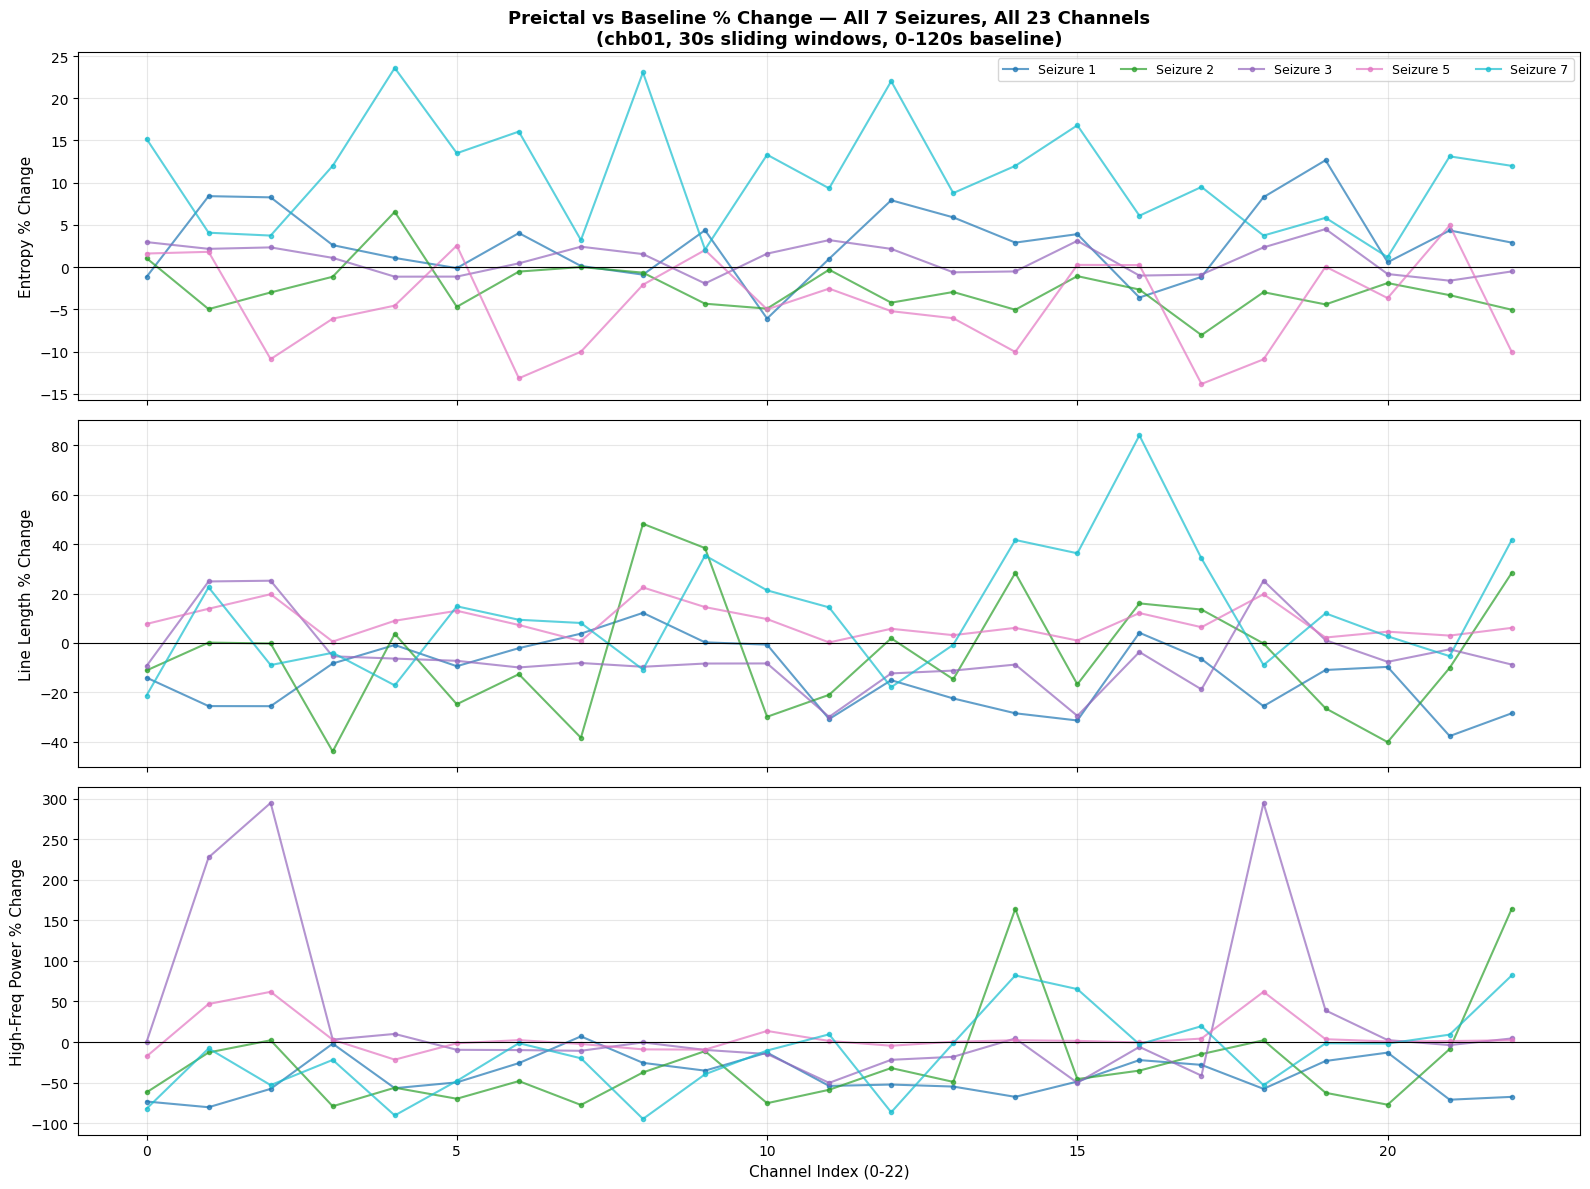

In [109]:
# Cell 9 - Chunk 3: Plot all 7 seizures

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

feature_keys   = ['entropy_change_%', 'line_length_change_%', 'hf_change_%']
feature_labels = ['Entropy % Change', 'Line Length % Change', 'High-Freq Power % Change']
colors = plt.cm.tab10(np.linspace(0, 0.9, 5))  # 7 colors now

for ax, fkey, flabel in zip(axes, feature_keys, feature_labels):
    for plot_idx, sz_idx in enumerate(valid_seizures):
        changes = [all_seizure_results[sz_idx][ch][fkey]
                   for ch in range(n_channels)
                   if ch in all_seizure_results[sz_idx]]
        ax.plot(range(len(changes)), changes,
                color=colors[plot_idx], alpha=0.7, linewidth=1.5,
                marker='o', markersize=3,
                label=f'Seizure {sz_idx+1}')

    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_ylabel(flabel, fontsize=11)
    ax.grid(True, alpha=0.3)

axes[0].set_title('Preictal vs Baseline % Change — All 7 Seizures, All 23 Channels\n(chb01, 30s sliding windows, 0-120s baseline)',
                  fontsize=13, fontweight='bold')
axes[0].legend(loc='upper right', fontsize=9, ncol=7)
axes[2].set_xlabel('Channel Index (0-22)', fontsize=11)

plt.tight_layout()
plt.savefig('all_seizures_feature_changes.png', dpi=300, bbox_inches='tight')
plt.show()

In [110]:
# Check which chb01 files have no seizures
seizure_files = [sz['file'] for sz in seizures_all]
print("Files WITH seizures:", seizure_files)

all_files = sorted([f for f in os.listdir('../data/chb01/') if f.endswith('.edf')])
print("\nAll files:")
for f in all_files:
    has_seizure = "SEIZURE" if f in seizure_files else "clean"
    print(f"  {f} — {has_seizure}")

Files WITH seizures: ['chb01_03.edf', 'chb01_04.edf', 'chb01_15.edf', 'chb01_16.edf', 'chb01_18.edf', 'chb01_21.edf', 'chb01_26.edf']

All files:
  chb01_03.edf — SEIZURE
  chb01_04.edf — SEIZURE
  chb01_15.edf — SEIZURE
  chb01_16.edf — SEIZURE
  chb01_18.edf — SEIZURE
  chb01_21.edf — SEIZURE
  chb01_26.edf — SEIZURE


In [111]:
# Read the summary file to find seizure onset channel
summary_file = '../data/chb01/chb01-summary.txt'

with open(summary_file, 'r') as f:
    content = f.read()

print(content)

Data Sampling Rate: 256 Hz
*************************

Channels in EDF Files:
**********************
Channel 1: FP1-F7
Channel 2: F7-T7
Channel 3: T7-P7
Channel 4: P7-O1
Channel 5: FP1-F3
Channel 6: F3-C3
Channel 7: C3-P3
Channel 8: P3-O1
Channel 9: FP2-F4
Channel 10: F4-C4
Channel 11: C4-P4
Channel 12: P4-O2
Channel 13: FP2-F8
Channel 14: F8-T8
Channel 15: T8-P8
Channel 16: P8-O2
Channel 17: FZ-CZ
Channel 18: CZ-PZ
Channel 19: P7-T7
Channel 20: T7-FT9
Channel 21: FT9-FT10
Channel 22: FT10-T8
Channel 23: T8-P8

File Name: chb01_01.edf
File Start Time: 11:42:54
File End Time: 12:42:54
Number of Seizures in File: 0

File Name: chb01_02.edf
File Start Time: 12:42:57
File End Time: 13:42:57
Number of Seizures in File: 0

File Name: chb01_03.edf
File Start Time: 13:43:04
File End Time: 14:43:04
Number of Seizures in File: 1
Seizure Start Time: 2996 seconds
Seizure End Time: 3036 seconds

File Name: chb01_04.edf
File Start Time: 14:43:12
File End Time: 15:43:12
Number of Seizures in File: 1
S

In [114]:
import os

clean_files = [
    'chb01_07.edf',
    'chb01_08.edf',
    'chb01_09.edf',
    'chb01_10.edf',
    'chb01_11.edf',
    'chb01_12.edf',
    'chb01_13.edf',
]

print("Checking downloaded files:\n")
for f in clean_files:
    filepath = f'../data/chb01/{f}'
    if os.path.exists(filepath):
        size = os.path.getsize(filepath) / (1024 * 1024)
        print(f"✓ {f} — {size:.1f} MB")
    else:
        print(f"✗ {f} — NOT FOUND")

Checking downloaded files:

✓ chb01_07.edf — 40.4 MB
✓ chb01_08.edf — 40.4 MB
✓ chb01_09.edf — 40.4 MB
✓ chb01_10.edf — 40.4 MB
✓ chb01_11.edf — 40.4 MB
✓ chb01_12.edf — 40.4 MB
✓ chb01_13.edf — 40.4 MB
